# 05 — Métricas y Comparación

Cuadro completo de métricas sobre el conjunto de test.


In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from discurso_odio.config import load_settings
from discurso_odio.data.loaders import load_all_splits, load_split, get_class_weights
from discurso_odio.paths import REPORTS_FIGURES, REPORTS_METRICS
from discurso_odio.utils.plotting import setup_plot_style, get_label_names, get_class_palette
from discurso_odio.utils.seed import set_seed

settings = load_settings()
set_seed(settings['project']['seed'])
setup_plot_style()
LABELS = get_label_names()
REPORTS_FIGURES.mkdir(parents=True, exist_ok=True)
REPORTS_METRICS.mkdir(parents=True, exist_ok=True)
print('Proyecto:', settings['project']['name'])

from discurso_odio.evaluation.metrics import compute_all_metrics, bootstrap_ci, mcnemar_test, f1_score
from discurso_odio.evaluation.slices import slice_metrics, dialect_bias_probe
from discurso_odio.models.mbert import predict
from discurso_odio.paths import MODELS_DIR
import json
import joblib
from sklearn.metrics import f1_score as sk_f1



Proyecto: discurso-odio-sv


In [2]:
test = load_split('test')
model_dir = MODELS_DIR / 'mbert-sv'
y_pred, y_prob = predict(test['texto_modelo'].tolist(), model_dir)
y_true = test['label'].values
metrics = compute_all_metrics(y_true, y_pred, y_prob)
print('F1-macro:', round(metrics['f1_macro'], 4))
print('Accuracy:', round(metrics['accuracy'], 4))
print('MAE ordinal:', round(metrics['ordinal_mae'], 4))
print(metrics['classification_report'])


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

F1-macro: 0.7777
Accuracy: 0.7826
MAE ordinal: 0.3239
                    precision    recall  f1-score   support

         No Tóxico       0.85      0.78      0.81       123
 Lenguaje Ofensivo       0.77      0.82      0.80       159
  Discurso de Odio       0.73      0.76      0.75        95
Amenazas/Violencia       0.77      0.75      0.76        83

          accuracy                           0.78       460
         macro avg       0.78      0.78      0.78       460
      weighted avg       0.78      0.78      0.78       460



In [3]:
# Intervalos de confianza bootstrap
f1_mean, f1_lo, f1_hi = bootstrap_ci(y_true, y_pred, lambda yt, yp: sk_f1(yt, yp, average='macro'))
acc_mean, acc_lo, acc_hi = bootstrap_ci(y_true, y_pred, lambda yt, yp: (yt==yp).mean())
print(f'F1-macro bootstrap: {f1_mean:.4f} [{f1_lo:.4f}, {f1_hi:.4f}]')
print(f'Accuracy bootstrap: {acc_mean:.4f} [{acc_lo:.4f}, {acc_hi:.4f}]')
print(f'Objetivo F1>0.80: {"CUMPLE" if f1_mean >= 0.80 else "NO CUMPLE"}')


F1-macro bootstrap: 0.7776 [0.7358, 0.8144]
Accuracy bootstrap: 0.7833 [0.7434, 0.8196]
Objetivo F1>0.80: NO CUMPLE


In [4]:
# McNemar vs baselines
mcnemar_results = []
for baseline_name in ['logisticregression', 'linearsvc', 'multinomialnb']:
    path = MODELS_DIR / f'baseline_{baseline_name}.joblib'
    if path.exists():
        pipe = joblib.load(path)
        bl_pred = pipe.predict(test['texto_modelo'])
        mcn = mcnemar_test(y_true, y_pred, bl_pred)
        mcnemar_results.append({'baseline': baseline_name, **mcn})
pd.DataFrame(mcnemar_results)


,baseline,statistic,p_value,b,c
0,logisticregression,0.564706,0.277999,48,37
1,linearsvc,0.540230,0.520292,47,40
2,multinomialnb,0.706349,0.000004,89,37


In [5]:
# Métricas por cortes
slices = slice_metrics(test, y_true, y_pred, y_prob)
bias = dialect_bias_probe(test, y_true, y_pred)
print('Sonda sesgo dialectal:', bias)
slice_summary = pd.DataFrame({k: {'f1_macro': v['f1_macro'], 'accuracy': v['accuracy']} for k,v in slices.items()}).T
slice_summary


Sonda sesgo dialectal: {'fpr_no_toxico_con_jerga': 0.41379310344827586, 'fpr_no_toxico_sin_jerga': 0.1595744680851064, 'n_no_toxico_con_jerga': 29, 'n_no_toxico_sin_jerga': 94}


,f1_macro,accuracy
plataforma_X,0.838632,0.842105
plataforma_Facebook,0.672663,0.724138
con_jerga,0.763194,0.794964
sin_jerga,0.689345,0.763736
sarcasmo_si,0.588121,0.744444
sarcasmo_no,0.792260,0.791892
ironia_si,0.524662,0.745763
ironia_no,0.787128,0.788030
contexto_politico_si,0.787474,0.869565
contexto_politico_no,0.760807,0.760870


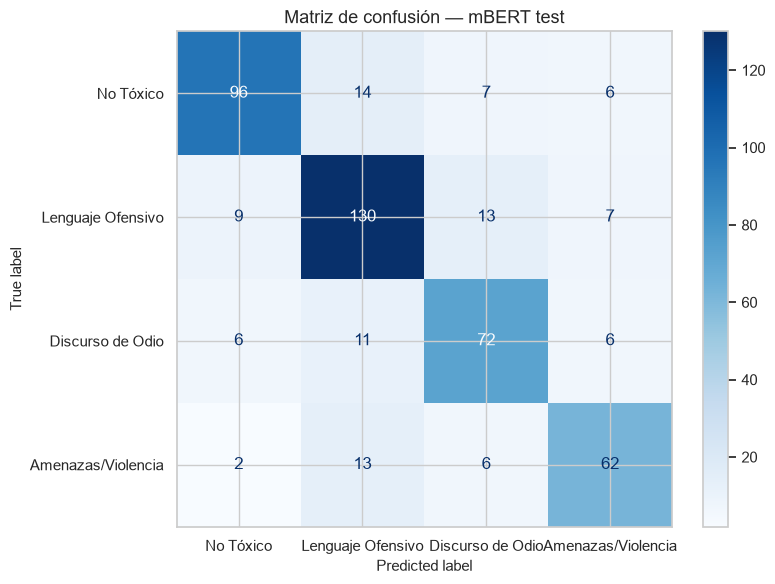

In [6]:
# Matriz de confusión
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=LABELS, ax=ax, cmap='Blues')
plt.title('Matriz de confusión — mBERT test')
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / '04_confusion_matrix.png')
plt.show()


In [7]:
# Exportar métricas
export = {k: v for k, v in metrics.items() if not isinstance(v, (list, dict))}
export['f1_bootstrap_lo'] = f1_lo
export['f1_bootstrap_hi'] = f1_hi
with open(MODELS_DIR / 'mbert-sv' / 'test_metrics.json', 'w') as f:
    json.dump(export, f, indent=2)
pd.DataFrame([export]).to_csv(REPORTS_METRICS / 'mbert_test_metrics.csv', index=False)
print('Métricas exportadas.')


Métricas exportadas.
